In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

Solutions are hidden: open them only after trying. Exercises 3, 6 and 10 are
also meant to be done with pen and paper. The exercises with Python use the
Madrid listings:

In [2]:
listings = pl.read_csv("data/processed/idealista/madrid_listings_2018.csv").select(
    "listing_id", "district", "zone", "condition",
    "price", "price_m2", "area_m2", "bedrooms", "bathrooms",
    "floor", "lift", "terrace", "construction_year", "dist_centre_km",
)

::: {#exr-lift-terrace}
## Lift and terrace

a) What type of variables are `lift` and `terrace`?
b) Compute the proportion of listings with a lift and with a terrace, and draw both
   in a single bar chart.
c) Is it correct to draw a pie chart of `lift`?
:::

::: {.callout-tip collapse="true"}
## Solution

a) Both are qualitative binary variables.

b) The mean of a binary variable is the proportion of `true` values:

In [3]:
shares = listings.select(pl.col("lift", "terrace").mean())
shares

lift,terrace
0.689,0.351


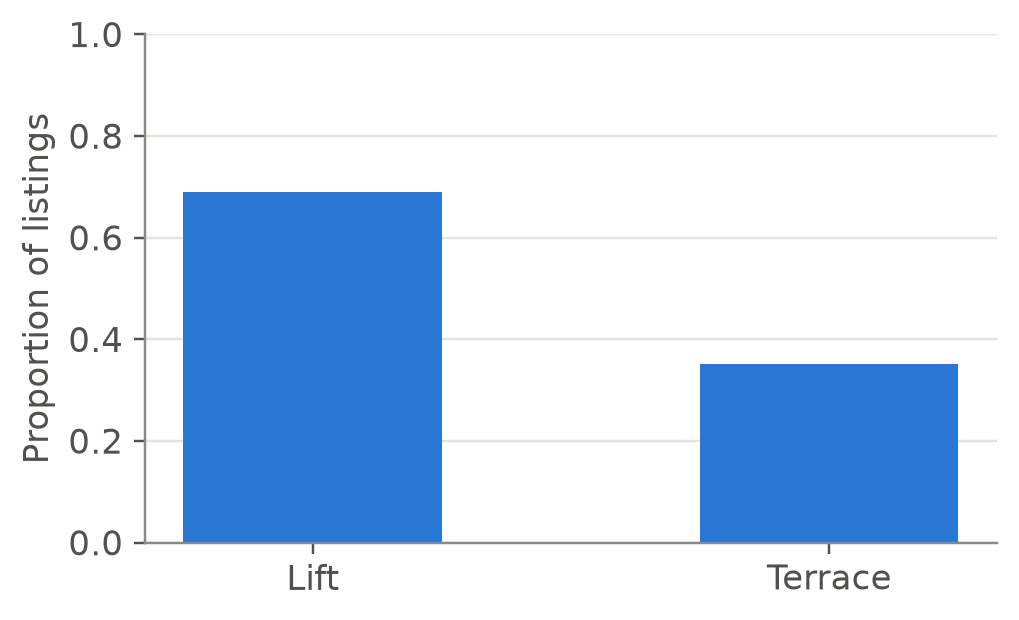

In [4]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["Lift", "Terrace"], shares.row(0), width=0.5, color=COLORS["blue"])
ax.set_ylim(0, 1)
ax.set_ylabel("Proportion of listings")
plt.show()

About 69 % of the listings are in a building with a lift, and 35 % have a terrace.

c) Yes. With two categories a pie chart is easy to read, although a single sentence
("69 % have a lift") says the same. What would be wrong is a single pie with "lift"
and "terrace" as slices: they are not categories of one variable, and a dwelling can
have both.
:::

::: {#exr-bathrooms}
## Number of bathrooms

a) Build the frequency table of `bathrooms`, with a last class "4 or more", including
   cumulative frequencies.
b) What are the mode and the median of the number of bathrooms?
c) What proportion of listings have at most two bathrooms?
:::

::: {.callout-tip collapse="true"}
## Solution

a)

In [5]:
bathrooms_table = (
    listings
    .with_columns(
        bathrooms=pl.when(pl.col("bathrooms") >= 4).then(pl.lit("4+"))
        .otherwise(pl.col("bathrooms").cast(pl.String))
    )
    .group_by("bathrooms")
    .agg(n_i=pl.len())
    .sort("bathrooms")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
bathrooms_table

bathrooms,n_i,f_i,F_i
0,70,0.001,0.001
1,"43,447",0.574,0.575
2,"24,783",0.327,0.902
3,5027,0.066,0.968
4+,2408,0.032,1.000


The class "0" holds a few listings with no bathroom, probably errors or premises
listed as dwellings.

b) The mode is 1 bathroom, the most frequent value. The median is also 1: the
cumulative frequency $F_i$ first exceeds 0.5 in the row of 1.

In [6]:
listings.select(mode=pl.col("bathrooms").mode(), median=pl.col("bathrooms").median())

mode,median
1,1.000


c) It is the cumulative relative frequency of the row "2": about 90 %.
:::

::: {#exr-grouped}
## Grouped data by hand

A property portal publishes only this table of the asking prices (thousands of €) of
the 200 flats for sale in a town:

| Class | $[50, 100)$ | $[100, 150)$ | $[150, 200)$ | $[200, 300)$ | $[300, 500)$ |
|---|---|---|---|---|---|
| $n_i$ | 20 | 50 | 45 | 65 | 20 |

: Asking prices in a town, grouped into classes of different widths.

a) Complete the table with $f_i$, $F_i$, the class marks $x_i$ and the densities
   $h_i = f_i / a_i$. Which is the most frequent class? Which is the modal class?
b) Compute the approximate mean, variance and standard deviation, using the
   computational formula for the variance.
c) Compute the approximate median and third quartile with the ogive.
:::

::: {.callout-tip collapse="true"}
## Solution

a) $f_i = 0.10, 0.25, 0.225, 0.325, 0.10$; $F_i = 0.10, 0.35, 0.575, 0.90, 1$; class marks
75, 125, 175, 250, 400; widths 50, 50, 50, 100, 200; densities (per thousand €)
0.0020, 0.0050, 0.0045, 0.00325, 0.0005. The most frequent class is $[200, 300)$, but it
is twice as wide as the first three; the **modal class**, the one with the greatest
density, is $[100, 150)$.

b) $\bar x \approx \sum f_i x_i = 7.5 + 31.25 + 39.375 + 81.25 + 40 = 199.375$, and
$\sum f_i x_i^2 = 562.5 + 3906.25 + 6890.625 + 20312.5 + 16000 = 47671.875$. By the
computational formula, $s^2 \approx 47671.875 - 199.375^2 \approx 7921.5$ and
$s \approx 89.0$ thousand €.

c) The median is in the first class with $F_i \ge 0.5$, $[150, 200)$:
$Me \approx 150 + \frac{0.5 - 0.35}{0.225}\cdot 50 \approx 183.3$. For $Q_{0.75}$ the class is
$[200, 300)$: $Q_{0.75} \approx 200 + \frac{0.75 - 0.575}{0.325}\cdot 100 \approx 253.8$.

In [7]:
lower = np.array([50, 100, 150, 200, 300]); upper = np.array([100, 150, 200, 300, 500])
n_i = np.array([20, 50, 45, 65, 20])
f = n_i / n_i.sum(); F = np.cumsum(f); mark = (lower + upper) / 2; width = upper - lower
mean = np.sum(f * mark); var = np.sum(f * mark**2) - mean**2

def grouped_quantile(p):
    i = np.argmax(F >= p)
    F_prev = F[i - 1] if i > 0 else 0.0
    return lower[i] + (p - F_prev) / f[i] * width[i]

print("densities:", np.round(f / width, 5))
print(f"mean {mean:.3f}, variance {var:.2f}, sd {np.sqrt(var):.2f}")
print(f"median {grouped_quantile(0.5):.2f}, Q3 {grouped_quantile(0.75):.2f}")

densities: [0.002  0.005  0.0045 0.0032 0.0005]
mean 199.375, variance 7921.48, sd 89.00
median 183.33, Q3 253.85


:::

::: {#exr-by-hand}
## Computing by hand

These are the asking prices, in thousands of euros, of the eight flats for sale in a
street:

$$
180, \quad 210, \quad 195, \quad 240, \quad 1150, \quad 205, \quad 225, \quad 190 .
$$

a) Compute the mean and the median. Which one describes better the price of a flat in
   this street?
b) Compute the variance $s^2$, the standard deviation $s$ and the corrected variance
   $\hat s^2$.
c) Compute the quartiles (with linear interpolation, as in NumPy) and the fences of
   the boxplot. Is there any outlier?
d) Repeat a) and b) without the flat of 1,150. What do you conclude?

Check your results with Python.
:::

::: {.callout-tip collapse="true"}
## Solution

a) Ordered: 180, 190, 195, 205, 210, 225, 240, 1150. The mean is
$\bar x = 2595 / 8 = 324.4$. With $n = 8$ (even), the median is the average of the two
central values, $(205 + 210)/2 = 207.5$. Seven of the eight flats cost between 180 and
240: the median describes them well, while the mean is above all of them except one.

b) The squared deviations from 324.375 add up to $\sum(x_i - \bar x)^2 \approx 781{,}622$,
so $s^2 = 781{,}622 / 8 \approx 97{,}703$, $s \approx 312.6$ and
$\hat s^2 = 781{,}622 / 7 \approx 111{,}660$. With $n = 8$, dividing by $n$ or by
$n - 1$ makes a visible difference.

c) With linear interpolation, the quartile $Q_p$ is at position $1 + p(n-1)$ of the
ordered data. For $Q_1$: position $1 + 0.25 \cdot 7 = 2.75$, between 190 and 195, so
$Q_1 = 190 + 0.75 \cdot 5 = 193.75$. For $Q_3$: position 6.25, so
$Q_3 = 225 + 0.25 \cdot 15 = 228.75$. Then $IQR = 35$, $LF = 141.25$ and
$UF = 281.25$: the flat of 1,150 is an outlier.

d) Without it, $\bar x = 1445/7 \approx 206.4$ and the median is 205: both now agree.
The standard deviation falls from about 313 to about 19. A single observation
dominated the mean and, even more, the standard deviation.

In [8]:
x = np.array([180, 210, 195, 240, 1150, 205, 225, 190])
q1, q3 = np.quantile(x, [0.25, 0.75])
print(f"mean {x.mean():.1f}, median {np.median(x):.1f}")
print(f"s^2 {x.var():,.1f}, s {x.std():.1f}, corrected variance {x.var(ddof=1):,.1f}")
print(f"Q1 {q1}, Q3 {q3}, fences [{q1 - 1.5 * (q3 - q1)}, {q3 + 1.5 * (q3 - q1)}]")
y = x[x != 1150]
print(f"without 1150: mean {y.mean():.1f}, median {np.median(y):.1f}, s {y.std():.1f}")

mean 324.4, median 207.5
s^2 97,702.7, s 312.6, corrected variance 111,660.3
Q1 193.75, Q3 228.75, fences [141.25, 281.25]
without 1150: mean 206.4, median 205.0, s 19.2


:::

::: {#exr-combine}
## Combining groups

The price per m² of the listings has these summaries by zone (standard deviations with
divisor $n_g$):

| Zone | $n_g$ | Mean (€/m²) | Standard deviation (€/m²) |
|---|---|---|---|
| Centre | 36,176 | 4,811 | 1,473 |
| Periphery | 39,559 | 2,562 | 1,096 |

: Price per m² by zone.

a) Compute the mean and the standard deviation of the price per m² of all the listings,
   without using the individual data.
b) What proportion of the variance is explained by the zone? Compare it with the
   proportion explained by the district in
   [part 3](03-dispersion-shape.ipynb#variance-within-and-between-groups).
c) Check a) with Python.
:::

::: {.callout-tip collapse="true"}
## Solution

a) With $n = 75{,}735$, the weights are $0.4777$ and $0.5223$. The mean is
$\bar x = 0.4777 \cdot 4811 + 0.5223 \cdot 2562 \approx 3636$ €/m². By the decomposition of
the variance, the within part is $0.4777 \cdot 1473^2 + 0.5223 \cdot 1096^2 \approx 1{,}664{,}000$
and the between part is
$0.4777(4811 - 3636)^2 + 0.5223(2562 - 3636)^2 \approx 1{,}262{,}000$, so
$s^2 \approx 2{,}926{,}000$ and $s \approx 1711$ €/m².

b) $\eta^2 \approx 1{,}262{,}000 / 2{,}926{,}000 \approx 0.43$. The district explains more
(0.59), because its 21 groups contain the 2 zones: splitting groups can only increase the
between part.

c)

In [9]:
listings.select(mean=pl.col("price_m2").mean(), std_dev=pl.col("price_m2").std(ddof=0))

mean,std_dev
"3,636.3","1,710.4"


:::

::: {#exr-shape-invariance}
## Shape does not depend on the units

Let $y_i = a + b\,x_i$ with $b \neq 0$.

a) Prove that the skewness coefficient satisfies $g_1(y) = g_1(x)$ if $b > 0$ and
   $g_1(y) = -g_1(x)$ if $b < 0$, and that the excess kurtosis does not change.
b) Prove that the coefficient of variation does not change if $a = 0$ and $b > 0$, but
   can change if $a \neq 0$.
c) Check a) with the prices in euros and in thousands of euros, and with $y = -x$.
:::

::: {.callout-tip collapse="true"}
## Solution

a) By the result on linear transformations, $y_i - \bar y = b(x_i - \bar x)$ and
$s_y = |b|\,s_x$. Hence
$$
g_1(y) = \frac{\frac1n\sum b^3(x_i - \bar x)^3}{|b|^3 s_x^3} = \frac{b^3}{|b|^3}\,g_1(x),
$$
and $b^3/|b|^3$ is the sign of $b$. For the kurtosis the powers are even, $b^4/|b|^4 = 1$.

b) $CV_y = |b|\,s_x / (a + b\bar x)$, which equals $s_x / \bar x$ when $a = 0$ and $b > 0$.
With $a \neq 0$ the denominator changes but the numerator does not.

c)

In [10]:
price = listings["price"]
pl.DataFrame({
    "variable": ["price (€)", "price (thousands of €)", "-price"],
    "skewness": [price.skew(), (price / 1000).skew(), (-price).skew()],
    "kurtosis": [price.kurtosis(), (price / 1000).kurtosis(), (-price).kurtosis()],
})

variable,skewness,kurtosis
price (€),4.074,29.472
price (thousands of €),4.074,29.472
-price,-4.074,29.472


:::

::: {#exr-area}
## Floor area

a) Draw a histogram of `area_m2` (up to 400 m²) and describe its shape.
b) Compute the mean, the median and the quartiles of the floor area.
c) A family looks for a flat of at least 150 m². What proportion of the listings
   meets this condition? Which percentile is 150 m², approximately?
:::

::: {.callout-tip collapse="true"}
## Solution

a)

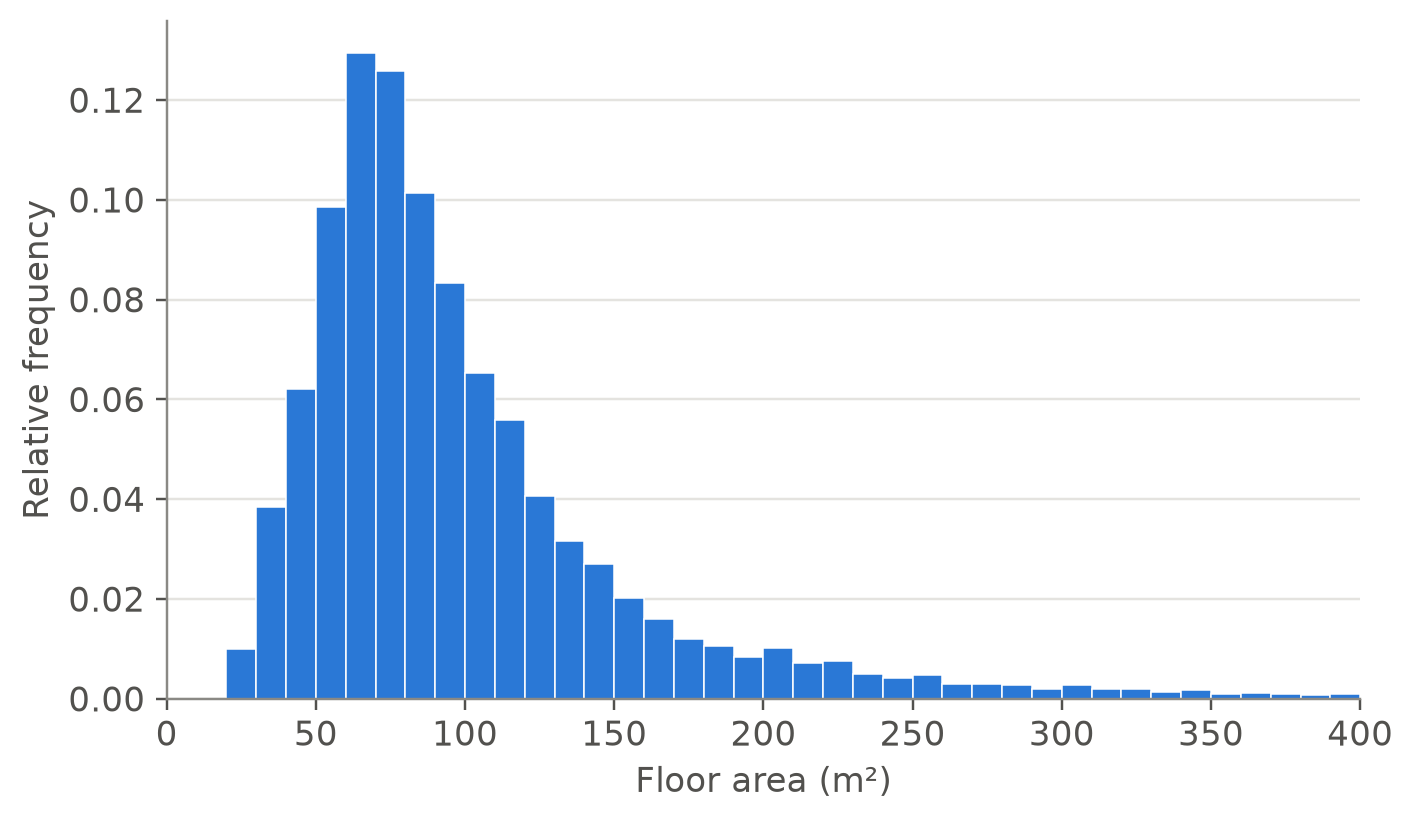

In [11]:
fig, ax = plt.subplots()
sns.histplot(x=listings["area_m2"].to_numpy(), bins=np.arange(0, 405, 10),
             stat="probability", color=COLORS["blue"], edgecolor="white",
             linewidth=0.5, alpha=1, ax=ax)
ax.set_xlim(0, 400)
ax.set_xlabel("Floor area (m²)")
ax.set_ylabel("Relative frequency")
plt.show()

The distribution is right-skewed, like the price: two thirds of the dwellings have between 50
and 120 m², and a long tail reaches several hundred square metres.

b)

In [12]:
listings.select(
    mean=pl.col("area_m2").mean(),
    Q1=pl.col("area_m2").quantile(0.25, "linear"),
    median=pl.col("area_m2").median(),
    Q3=pl.col("area_m2").quantile(0.75, "linear"),
)

mean,Q1,median,Q3
100.221,62.000,82.000,115.000


As expected with right skewness, the mean (about 100 m²) is larger than the median
(82 m²).

c)

In [13]:
share = (listings["area_m2"] >= 150).mean()
print(f"Proportion with at least 150 m²: {share:.3f}")

Proportion with at least 150 m²: 0.137


About 14 % of the listings have 150 m² or more, so 150 m² is approximately the
86th percentile: it leaves about 86 % of the listings below it.
:::

::: {#exr-zone}
## Centre and periphery

a) Compute, for each zone, the number of listings and the mean, median, standard
   deviation and coefficient of variation of the price per m².
b) Draw boxplots of the price per m² in the two zones.
c) In which zone are prices per m² higher? In which one are they more dispersed, in
   absolute terms and relative to the mean?
:::

::: {.callout-tip collapse="true"}
## Solution

a)

In [14]:
x = pl.col("price_m2")
(
    listings.group_by("zone")
    .agg(n=pl.len(), mean=x.mean(), median=x.median(),
         std_dev=x.std(ddof=0), CV=x.std(ddof=0) / x.mean())
    .sort("zone")
)

zone,n,mean,median,std_dev,CV
Centre,"36,176","4,811.1","4,623.6","1,472.8",0.306
Periphery,"39,559","2,562.0","2,300.0","1,096.0",0.428


b)

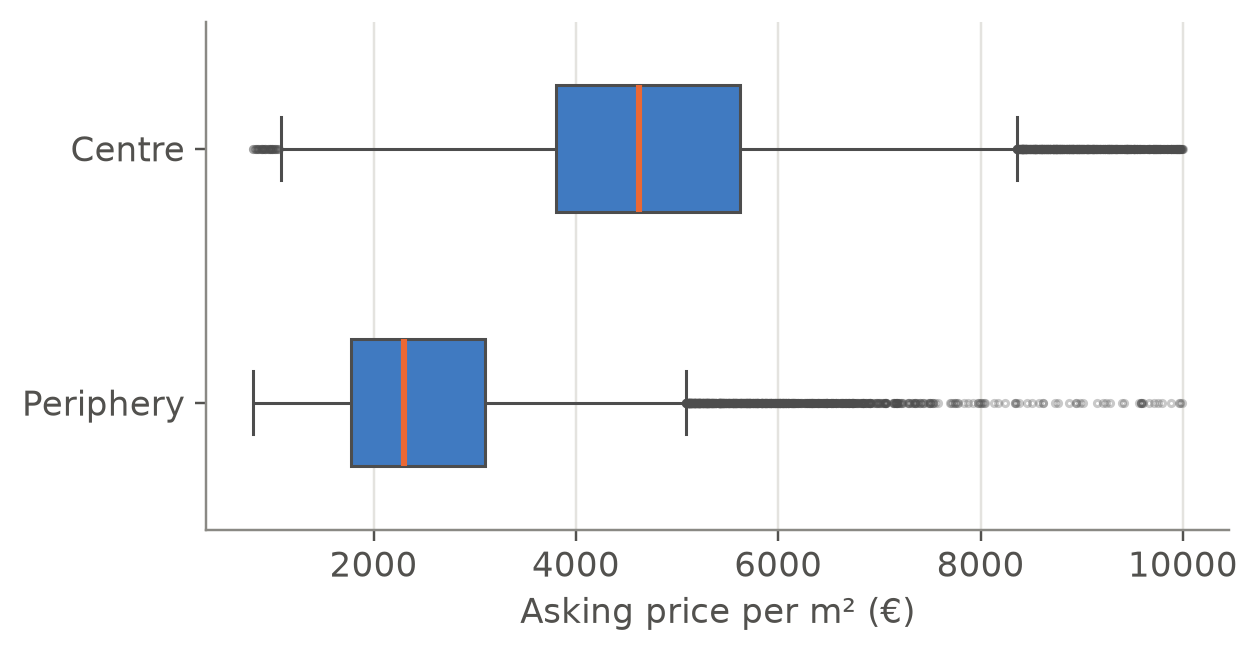

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(x=listings["price_m2"].to_numpy(), y=listings["zone"].to_numpy(),
            order=["Centre", "Periphery"],
            color=COLORS["blue"], width=0.5,
            medianprops=dict(color=COLORS["orange"], linewidth=2),
            flierprops=dict(marker="o", markersize=2, alpha=0.3), ax=ax)
ax.set_xlabel("Asking price per m² (€)")
ax.set_ylabel("")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

c) The median price per m² in the centre (about 4,600 €) is about twice that of the
periphery (2,300 €). The centre also has a larger standard deviation, but relative
to its mean its spread is smaller: its coefficient of variation is lower. The
periphery is more heterogeneous, because it mixes neighbourhoods as different as
those of Moncloa-Aravaca and Villaverde.
:::

::: {#exr-units}
## Change of units

A British investor wants the floor area in square feet (1 m² = 10.764 ft²) and the
price in thousands of euros.

a) Without using the data, how do the mean, the standard deviation and the
   coefficient of variation of the area change when it is expressed in ft²?
b) Check it with Python, for the area and for the price.
c) The investor also wants a variable "area above 90 m²", $y_i = x_i - 90$. How do its
   mean, standard deviation and coefficient of variation compare with those of the
   area?
:::

::: {.callout-tip collapse="true"}
## Solution

a) By the result on linear transformations of
[part 3](03-dispersion-shape.ipynb#linear-transformations-and-standardisation), with
$y = 10.764\,x$ the mean and the standard deviation are multiplied by 10.764, and the
coefficient of variation, their ratio, does not change. It has no units.

b)

In [16]:
def summary(s: pl.Series) -> dict:
    return {"mean": s.mean(), "std_dev": s.std(ddof=0), "CV": s.std(ddof=0) / s.mean()}

pl.DataFrame([
    {"variable": "area (m²)", **summary(listings["area_m2"])},
    {"variable": "area (ft²)", **summary(listings["area_m2"] * 10.764)},
    {"variable": "price (€)", **summary(listings["price"])},
    {"variable": "price (thousands of €)", **summary(listings["price"] / 1000)},
])

variable,mean,std_dev,CV
area (m²),100.221,66.412,0.663
area (ft²),"1,078.8",714.858,0.663
price (€),"388,892.1","412,406.6",1.060
price (thousands of €),388.892,412.407,1.060


c) With $a = -90$ and $b = 1$, the mean decreases by 90 m² and the standard deviation
does not change. The coefficient of variation does change, because the mean changes
but the standard deviation does not: the CV only makes sense on a ratio scale, with a
true zero, and "area above 90 m²" has lost it (it can even be negative).
:::

::: {#exr-chebyshev-sharp}
## Chebyshev's bound cannot be improved

Consider the eight observations $-1, 0, 0, 0, 0, 0, 0, 1$.

a) Compute $\bar x$ and $s$.
b) What proportion of the observations satisfies $|x_i - \bar x| \ge 2s$? Compare it with
   the bound of Chebyshev's inequality for $k = 2$.
c) Why does this show that, without further information on the data, the bound $1/k^2$
   cannot be lowered?
:::

::: {.callout-tip collapse="true"}
## Solution

a) $\bar x = 0$ and $s^2 = \frac18(1 + 1) = \frac14$, so $s = \frac12$.

b) $2s = 1$, and the observations with $|x_i| \ge 1$ are $-1$ and $1$: a proportion of
$2/8 = 1/4$, exactly the bound $1/k^2 = 1/4$.

c) The inequality claims that the proportion is **at most** $1/k^2$ for **every** data
set. Since here the proportion equals $1/4$, no smaller number can be a valid bound for
all data sets. The bound is attained when the observations far from the mean are all
exactly at distance $ks$ and the rest are exactly at the mean, which is what the proof
shows: equality requires both inequalities in it to be equalities.
:::

## References {.unnumbered}

::: {#refs}
:::